In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
# from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Load data
df = pd.read_csv('stock_data(ZTS).csv')

# Do preprocessing by normalizing data
# make a function to grab current time in seconds
# Create a multiplier on the volume portion(most likely seconds/60)
# Run LSTM
# Do preprocessing to denormalize data


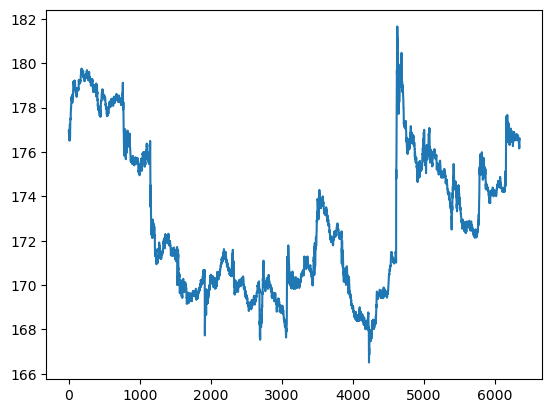

In [71]:
plt.plot(df['High'])

In [72]:
# scaler = MinMaxScaler(feature_range=(0, 1))
# scale_X = scaler.fit_transform(df[['Open', 'Low', 'Close', 'Adj Close', 'Volume']])
# scale_y = scaler.fit_transform(np.reshape(a = df['High'], newshape = (-1, 1)))
# display(scale_X)


In [2]:
# def rolling_window():
    # grab values for everything and place it in
    #start at the 5th value as the target. grab all previous vlaues and mark them in seperate columns
# Define the window size
window_size = 5

columns = []
for i in range(1, window_size + 1):
    columns += [f'F{i} Open', f'F{i} High', f'F{i} Low', f'F{i} Close', f'F{i} Adj Close', f'F{i} Volume']

windowed_df = pd.DataFrame(columns=columns)

for i in range(len(df) - window_size + 1):
    window_data = []
    for j in range(window_size):
        row = df.iloc[i + j][['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].values
        window_data.extend(row)
    
    windowed_df.loc[i] = window_data

windowed_df.drop(axis = 1, labels = ['F5 Open', 'F5 Low', 'F5 Close', 'F5 Adj Close', 'F5 Volume'], inplace = True)

windowed_df.rename(columns = {'F5 High':'Target High'}, inplace = True)


display(windowed_df)
# we can use one of our min max training rows as our current information and also divide the volume by sec/60

,F1 Open,F1 High,F1 Low,F1 Close,F1 Adj Close,F1 Volume,F2 Open,F2 High,F2 Low,F2 Close,...,F3 Close,F3 Adj Close,F3 Volume,F4 Open,F4 High,F4 Low,F4 Close,F4 Adj Close,F4 Volume,Target High
0,176.570007,176.899994,176.020004,176.690002,176.690002,24236.0,176.649994,177.000000,176.550003,176.737900,...,176.589996,176.589996,6012.0,176.570007,176.570007,176.399994,176.494995,176.494995,4557.0,176.610001
1,176.649994,177.000000,176.550003,176.737900,176.737900,3267.0,176.774994,176.774994,176.529999,176.589996,...,176.494995,176.494995,4557.0,176.494995,176.610001,176.494995,176.610001,176.610001,4300.0,176.604996
2,176.774994,176.774994,176.529999,176.589996,176.589996,6012.0,176.570007,176.570007,176.399994,176.494995,...,176.610001,176.610001,4300.0,176.490005,176.604996,176.229996,176.380005,176.380005,6852.0,176.880005
3,176.570007,176.570007,176.399994,176.494995,176.494995,4557.0,176.494995,176.610001,176.494995,176.610001,...,176.380005,176.380005,6852.0,176.365005,176.880005,176.365005,176.830002,176.830002,6056.0,176.843506
4,176.494995,176.610001,176.494995,176.610001,176.610001,4300.0,176.490005,176.604996,176.229996,176.380005,...,176.830002,176.830002,6056.0,176.843506,176.843506,176.720001,176.740005,176.740005,4049.0,176.649994
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6343,176.139999,176.160004,176.100006,176.149994,176.149994,2779.0,176.145004,176.199997,176.119995,176.199997,...,176.169998,176.169998,2953.0,176.195007,176.389999,176.195007,176.350006,176.350006,4315.0,176.440002
6344,176.145004,176.199997,176.119995,176.199997,176.199997,2790.0,176.240005,176.240005,176.169998,176.169998,...,176.350006,176.350006,4315.0,176.350006,176.440002,176.330002,176.440002,176.440002,4192.0,176.570007
6345,176.240005,176.240005,176.169998,176.169998,176.169998,2953.0,176.195007,176.389999,176.195007,176.350006,...,176.440002,176.440002,4192.0,176.440002,176.570007,176.440002,176.490005,176.490005,19101.0,176.570007
6346,176.195007,176.389999,176.195007,176.350006,176.350006,4315.0,176.350006,176.440002,176.330002,176.440002,...,176.490005,176.490005,19101.0,176.520004,176.570007,176.520004,176.547501,176.547501,8354.0,176.580002


In [3]:
scaler = MinMaxScaler()

X_scale = scaler.fit_transform(windowed_df[['F1 Open', 'F1 High', 'F1 Low', 'F1 Close', 'F1 Adj Close', 'F1 Volume',
       'F2 Open', 'F2 High', 'F2 Low', 'F2 Close', 'F2 Adj Close', 'F2 Volume',
       'F3 Open', 'F3 High', 'F3 Low', 'F3 Close', 'F3 Adj Close', 'F3 Volume',
       'F4 Open', 'F4 High', 'F4 Low', 'F4 Close', 'F4 Adj Close', 'F4 Volume']])
y_scale = scaler.fit_transform(windowed_df[['Target High']])

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X_scale, y_scale, train_size = .7)

y_train.shape, X_test.shape

((4443, 1), (1905, 24))

In [5]:
X_train = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
y_train = y_train.reshape(y_train.shape[0], 1, y_train.shape[1])

X_test = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])

In [6]:
model = Sequential()

model.add(LSTM(units=50, return_sequences=True))
model.add(LSTM(units=50, return_sequences=True))
model.add(LSTM(units=50))
model.add(Dense(units=1))
model.compile(loss = 'mean_squared_error', optimizer = 'adam')

In [17]:
model.fit(X_train, y_train, batch_size = 1, verbose = 1, epochs = 1)

4443/4443 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 1.4180e-04


In [11]:
predicted = model.predict(X_test)

predicted = scaler.inverse_transform(predicted)
y_test = scaler.inverse_transform(y_test)

y_test.shape, predicted.shape


60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


((1905, 1), (1905, 1))

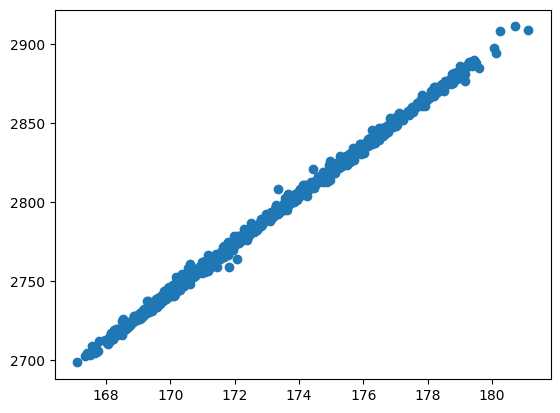

In [12]:
plt.scatter(predicted, y_test)

In [18]:
r2 = r2_score(y_true = y_test, y_pred = predicted)
print(f'R2 SCORE: {r2}')
# f1 = f1_score(y_true = y_test, y_pred = predicted)

R2 SCORE: -2729.3342249478223


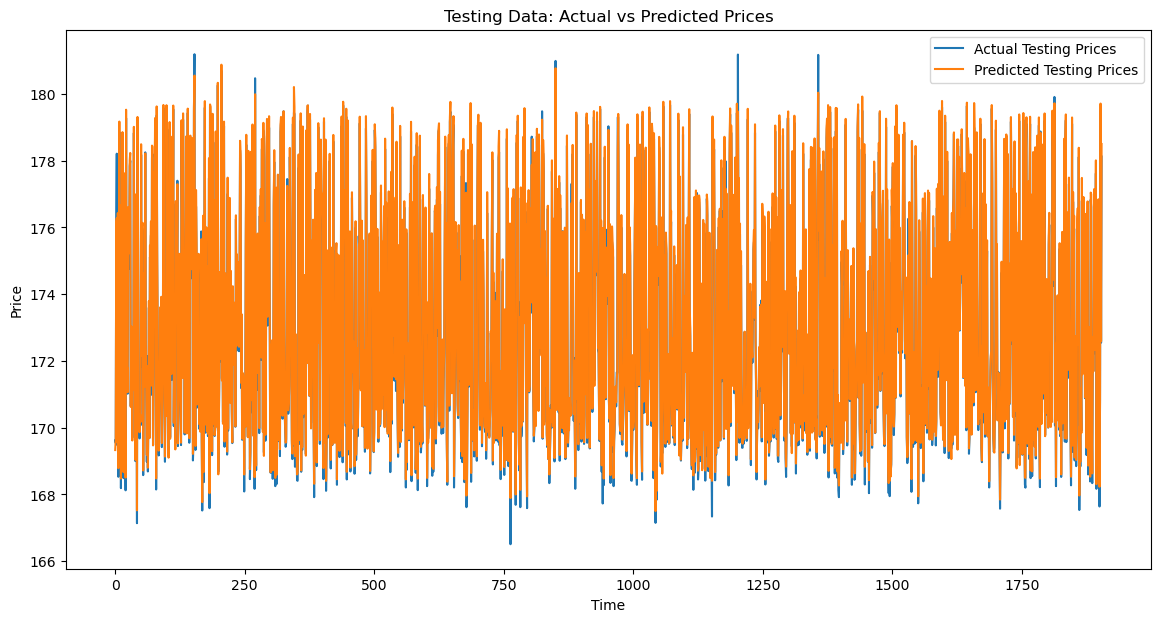

In [84]:
plt.figure(figsize=(14, 7))
plt.plot(y_test, label='Actual Testing Prices')
plt.plot(predicted, label='Predicted Testing Prices')
plt.title('Testing Data: Actual vs Predicted Prices')
plt.xticks()
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()